# Capstone Project: Analysing Insurance Claims for SafeDrive Insurance Ltd.

## Stage 2: Model Building and Validation

This notebook covers Stage 2 of the capstone project. The objective is to use the cleaned dataset prepared in Stage 1, prepare the modelling data, split it into training and testing sets, build a Logistic Regression baseline model, and evaluate the model using classification metrics.

## 1. Objective of Stage 2

The objective of this stage is to build a baseline machine learning model that predicts whether a policyholder is likely to file an insurance claim.

The target variable is `is_claim`, where:

- `0` means No Claim
- `1` means Claim Filed

Logistic Regression is used as the baseline model because it is simple, interpretable, and suitable for binary classification problems.

## 2. Import Required Libraries

The required libraries are imported for data handling, train-test splitting, scaling, model building, and model evaluation.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

## 3. Load the Cleaned Dataset

The cleaned dataset exported from Stage 1 is loaded. This dataset contains encoded variables, engineered features, the policy identifier, and the target variable.

In [2]:
# Loading cleaned dataset

df = pd.read_csv("cleaned_dataset.csv")

# Displaying first 5 rows
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,...,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety,is_claim
0,ID00001,0.515874,0.05,0.644231,4990.0,1.0,2.0,796.0,3.0,5.0,...,1,1,0,0,0,0,1,0,0,0
1,ID00002,0.672619,0.02,0.375000,27003.0,1.0,2.0,796.0,3.0,5.0,...,1,0,0,0,1,0,0,0,0,0
2,ID00003,0.841110,0.02,0.384615,4076.0,1.0,2.0,796.0,3.0,5.0,...,1,0,0,0,1,0,0,0,0,0
3,ID00004,0.900277,0.11,0.432692,21622.0,1.0,2.0,1197.0,4.0,5.0,...,1,0,1,0,1,0,0,0,1,0
4,ID00005,0.596403,0.11,0.634615,34738.0,2.0,2.0,999.0,3.0,5.0,...,1,0,1,0,0,0,1,1,0,0


### Observation

The cleaned dataset has been loaded successfully. It contains model-ready numerical features along with `policy_id` for traceability and `is_claim` as the target variable.

## 4. Basic Dataset Check

The shape, data types, missing values, and duplicate records are checked again before model building to ensure that the dataset is ready for training.

In [3]:
# Checking dataset shape

df.shape

(58592, 102)

In [4]:
# Checking dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Columns: 102 entries, policy_id to is_claim
dtypes: float64(22), int64(79), object(1)
memory usage: 45.6+ MB


In [5]:
# Checking missing values

df.isnull().sum().sum()

np.int64(0)

In [6]:
# Checking duplicate records

df.duplicated().sum()

np.int64(0)

### Observation

The cleaned dataset has no missing values or duplicate records. Therefore, it can be used for model preparation.

## 5. Target Variable Distribution

Before splitting the data, the target variable distribution is checked again to understand the class imbalance.

In [7]:
# Checking target variable count

df["is_claim"].value_counts()

is_claim
0    54844
1     3748
Name: count, dtype: int64

In [8]:
# Checking target variable percentage

df["is_claim"].value_counts(normalize=True) * 100

is_claim
0    93.603222
1     6.396778
Name: proportion, dtype: float64

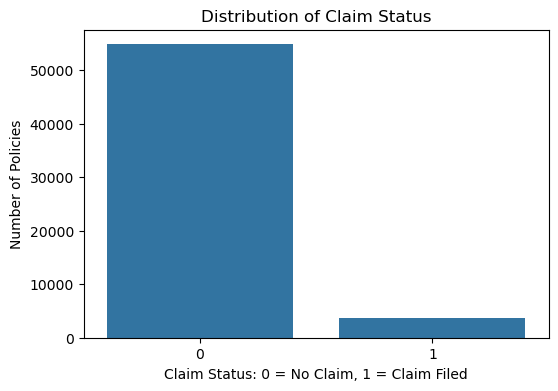

In [9]:
# Visualising target variable distribution

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_claim")
plt.title("Distribution of Claim Status")
plt.xlabel("Claim Status: 0 = No Claim, 1 = Claim Filed")
plt.ylabel("Number of Policies")
plt.show()

### Observation

The target variable is imbalanced, with a much higher number of no-claim records compared to claim records. Therefore, accuracy alone will not be sufficient for model evaluation. Precision, Recall, F1 Score, and ROC-AUC will also be used.

## 6. Separating Features and Target Variable

The dataset is divided into input features `X` and target variable `y`.

The `policy_id` column is removed from the feature set because it is only an identifier and does not carry predictive meaning.

In [10]:
# Separating input features and target variable

X = df.drop(columns=["policy_id", "is_claim"], errors="ignore")
y = df["is_claim"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (58592, 100)
Shape of y: (58592,)


## 7. Train-Test Split

The data is split into training and testing sets using an 80/20 ratio.

The training set is used to train the model, while the testing set is kept unseen and used only for final model evaluation.

Since the target variable is imbalanced, stratified splitting is used to maintain the same claim/no-claim proportion in both training and testing datasets.

In [11]:
# Performing 80/20 train-test split with stratification

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (46873, 100)
X_test shape: (11719, 100)
y_train shape: (46873,)
y_test shape: (11719,)


In [12]:
# Checking target distribution in training and testing sets

print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
is_claim
0    93.603994
1     6.396006
Name: proportion, dtype: float64

Testing target distribution:
is_claim
0    93.600137
1     6.399863
Name: proportion, dtype: float64


### Observation

The dataset has been split into training and testing sets using an 80/20 ratio. Stratification ensures that the proportion of claim and no-claim records remains similar in both sets.

## 8. Leakage Prevention

Data leakage happens when information from the test set is used during model training. This can make model performance look better than it actually is.

To prevent leakage:

- The model will be trained only on the training dataset.
- The scaler will be fitted only on the training data.
- The fitted scaler will then be applied to the test data.
- The target variable `is_claim` and identifier column `policy_id` are not included in the input features.

## 9. Feature Scaling

Logistic Regression is sensitive to feature scale. Therefore, StandardScaler is used to standardise the input features.

The scaler is fitted only on the training data and then applied to both training and testing data.

In [13]:
# Scaling the features

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same fitted scaler
X_test_scaled = scaler.transform(X_test)

# Converting scaled arrays back to DataFrames
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

X_train_scaled.head()

,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,...,is_ecw_Yes,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety
47135,-0.769378,2.011600,0.013118,1.107773,-0.672729,-0.620668,0.127249,0.769199,0.0,-0.233824,...,0.615023,0.079583,-0.536263,-0.545325,2.094980,-0.638401,1.583480,-0.554834,-0.412643,0.850864
58128,-0.527624,0.379312,-1.087333,-0.828234,-0.672729,-0.620668,-0.620685,-1.300054,0.0,-0.672560,...,0.615023,0.079583,-0.536263,1.833770,-0.477332,-0.638401,-0.631521,-0.554834,2.423401,-1.175276
35000,1.100508,-0.708879,1.113569,-0.604848,-0.672729,-0.620668,0.127249,0.769199,0.0,-0.233824,...,0.615023,0.079583,-0.536263,-0.545325,-0.477332,-0.638401,-0.631521,1.802342,-0.412643,0.850864
6078,-0.022301,0.197947,1.427984,1.107773,-0.672729,-0.620668,0.127249,0.769199,0.0,-0.233824,...,0.615023,0.079583,-0.536263,1.833770,-0.477332,-0.638401,-0.631521,1.802342,-0.412643,0.850864
34780,0.525442,-1.071610,0.484740,-0.828234,-0.672729,-0.620668,-1.379895,-1.300054,0.0,-1.111295,...,-1.625956,0.079583,-0.536263,-0.545325,-0.477332,-0.638401,1.583480,-0.554834,-0.412643,-1.175276


In [14]:
# Checking scaled training data summary

X_train_scaled.describe().T.head()

,count,mean,std,min,25%,50%,75%,max
policy_tenure,46873.0,1.440095e-16,1.000011,-1.470033,-0.971023,-0.089008,1.031083,1.890929
age_of_car,46873.0,-1.447674e-16,1.000011,-1.252975,-0.890244,-0.164783,0.742043,3.190474
age_of_policyholder,46873.0,-3.031778e-18,1.000011,-1.480352,-0.772919,-0.144089,0.641947,2.882151
population_density,46873.0,1.167235e-16,1.000011,-1.166216,-0.781893,-0.604848,0.597168,2.665761
make,46873.0,9.034700e-17,1.000011,-0.672729,-0.672729,-0.672729,1.081971,2.836670


### Observation

Feature scaling has been applied using StandardScaler. The scaler was fitted only on the training data and then applied to the test data, which prevents data leakage.

## 10. Logistic Regression Assumption: Independence of Observations

Logistic Regression assumes that each observation is independent.

In this dataset, each row represents one insurance policy record. Since every policy record is treated as a separate observation, the independence assumption is reasonably satisfied.

## 11. Logistic Regression Baseline Model

A Logistic Regression model is trained as the baseline model.

Because the dataset is imbalanced, `class_weight="balanced"` is used. This gives more importance to the minority class, which is the claim class.

In [15]:
# Building Logistic Regression baseline model

log_reg_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Training the model
log_reg_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### Observation

The Logistic Regression baseline model has been trained successfully. Class balancing was used because the dataset contains far fewer claim records than no-claim records.

## 12. Model Predictions

The trained Logistic Regression model is used to generate predictions on the unseen test data.

Two outputs are generated:

- Predicted class: 0 or 1
- Predicted probability: probability of filing a claim

In [16]:
# Making predictions on test data

y_pred = log_reg_model.predict(X_test_scaled)

# Predicting probability for claim class
y_pred_proba = log_reg_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [17]:
# Previewing predictions

prediction_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Claim_Probability": y_pred_proba
})

prediction_preview.head()

,Actual,Predicted,Claim_Probability
0,0,1,0.556297
1,0,0,0.341703
2,0,0,0.420061
3,0,1,0.577991
4,0,0,0.370307


### Observation

The model has generated predicted claim classes and claim probabilities for the test dataset. These predictions will be evaluated using classification metrics.

## 13. Model Evaluation

The Logistic Regression baseline model is evaluated on the test dataset using multiple classification metrics.

Since the dataset is imbalanced, accuracy alone is not enough. Therefore, Precision, Recall, F1 Score, and ROC-AUC are also calculated.

In [18]:
# Calculating evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
})

metrics_df

,Metric,Score
0,Accuracy,0.574793
1,Precision,0.082132
2,Recall,0.554667
3,F1 Score,0.143078
4,ROC-AUC,0.591438


### Observation

The evaluation metrics show the baseline performance of the Logistic Regression model. Since the claim class is the minority class, Recall and F1 Score are especially important along with ROC-AUC.

## 14. Confusion Matrix

A confusion matrix is used to understand how many claim and no-claim records were correctly or incorrectly predicted by the model.

It shows:

- True Negatives: No-claim cases correctly predicted as no claim
- False Positives: No-claim cases incorrectly predicted as claim
- False Negatives: Claim cases incorrectly predicted as no claim
- True Positives: Claim cases correctly predicted as claim

In [19]:
# Creating confusion matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[6320, 4649],
       [ 334,  416]])

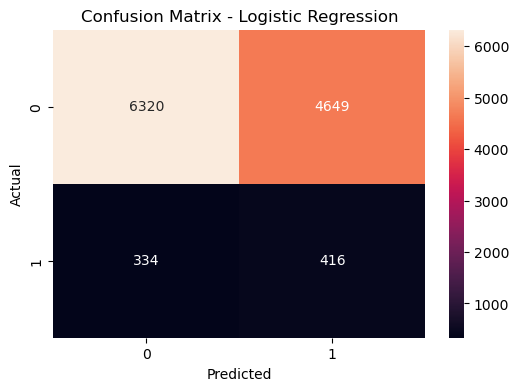

In [20]:
# Visualising confusion matrix

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation

The confusion matrix helps identify how well the model predicts both claim and no-claim cases. In insurance claim prediction, reducing false negatives is important because missing actual claim cases can increase business risk.

## 15. Classification Report

The classification report provides Precision, Recall, F1 Score, and Support for each class separately.

In [21]:
# Displaying classification report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.95      0.58      0.72     10969
           1       0.08      0.55      0.14       750

    accuracy                           0.57     11719
   macro avg       0.52      0.57      0.43     11719
weighted avg       0.89      0.57      0.68     11719



### Observation

The classification report gives class-wise performance. Since claim cases are fewer, the performance for class `1` should be reviewed carefully. The model should ideally identify claim cases without creating too many false alarms.

## 16. ROC Curve and ROC-AUC Score

The ROC curve shows how well the model separates claim and no-claim cases across different classification thresholds.

ROC-AUC closer to 1 indicates better separation between the two classes.

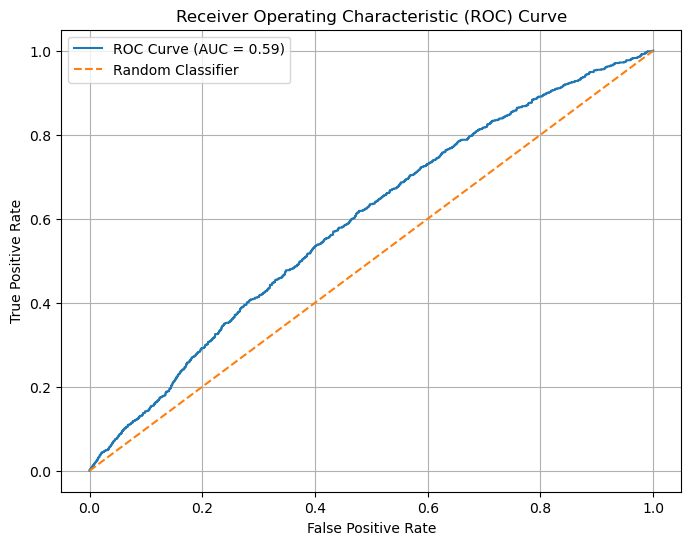

In [22]:
# Calculating ROC curve values

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc_value = auc(fpr, tpr)

# Plotting ROC curve

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_value:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The ROC curve shows the trade-off between true positive rate and false positive rate at different thresholds. The ROC-AUC score will be used as one of the key metrics to compare this baseline model with the Decision Tree model in Stage 3.

## 17. Feature Importance Using Logistic Regression Coefficients

Logistic Regression coefficients help understand the direction and strength of feature impact.

A positive coefficient means the feature increases the predicted probability of claim, while a negative coefficient means the feature decreases the predicted probability of claim.

In [23]:
# Creating coefficient dataframe

coef_df = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": log_reg_model.coef_[0]
})

# Sorting by absolute coefficient value
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df_sorted = coef_df.sort_values(by="Abs_Coefficient", ascending=False)

coef_df_sorted.head(20)

,Feature,Coefficient,Abs_Coefficient
1,age_of_car,-0.417433,0.417433
0,policy_tenure,0.387186,0.387186
94,car_age_group_Very_Old,0.225997,0.225997
93,car_age_group_Old,0.183093,0.183093
2,age_of_policyholder,0.123901,0.123901
97,policyholder_age_group_Senior,-0.118396,0.118396
37,area_cluster_C3,0.108458,0.108458
42,area_cluster_C8,0.068687,0.068687
33,area_cluster_C2,0.067574,0.067574
31,area_cluster_C18,0.055507,0.055507


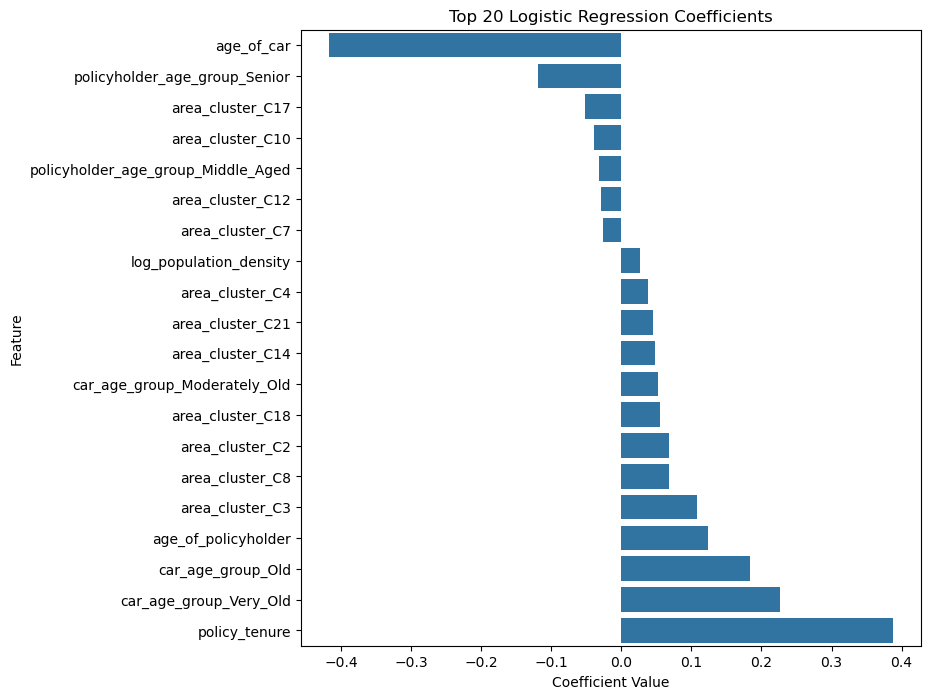

In [24]:
# Visualising top 20 important features

top_20_coef = coef_df_sorted.head(20).sort_values(by="Coefficient")

plt.figure(figsize=(8, 8))
sns.barplot(data=top_20_coef, x="Coefficient", y="Feature")
plt.title("Top 20 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.show()

### Observation

The coefficient analysis helps identify which features have the strongest positive or negative relationship with claim prediction. Positive coefficients push the prediction toward claim, while negative coefficients push it toward no claim.

These coefficients provide interpretability and help explain the baseline Logistic Regression model in business terms.

## 18. Baseline Model Summary

The Logistic Regression model has been built and evaluated as the baseline model.

Key points:

- The model was trained on the scaled training dataset.
- Class balancing was applied due to target imbalance.
- The model was evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.
- Confusion matrix and classification report were used to understand class-wise performance.
- Logistic Regression coefficients were analysed to understand feature impact.

## 19. Strengths and Weaknesses of the Baseline Model

### Strengths

- Logistic Regression is simple and interpretable.
- It provides coefficients that help explain feature impact.
- It works well as a baseline for binary classification.
- Class balancing helps address the imbalanced target variable.

### Weaknesses

- Logistic Regression assumes a mostly linear relationship between features and log-odds of the target.
- It may not capture complex non-linear claim-risk patterns.
- Performance on minority claim cases may still be limited due to class imbalance.
- More advanced models such as Decision Trees may capture non-linear relationships better.

## 20. Stage 2 Summary

Stage 2 of the capstone project has been completed.

The following tasks were performed:

- Cleaned dataset from Stage 1 was loaded.
- Input features and target variable were separated.
- The dataset was split into training and testing sets using an 80/20 split.
- Stratification was used to preserve target class balance.
- Feature scaling was applied with leakage prevention.
- Logistic Regression baseline model was trained.
- Model predictions and claim probabilities were generated.
- Model performance was evaluated using Accuracy, Precision, Recall, F1 Score, ROC-AUC, confusion matrix, classification report, and ROC curve.
- Feature coefficients were reviewed for interpretability.

This Logistic Regression model will be used as the baseline model for comparison with the Decision Tree model in Stage 3.